In [29]:
import os
import random
import shutil
import yaml
import json
import time
import glob
import math
import warnings

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_NAME = "Underwater_Fish_Detection_YOLO11"

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

OUTPUT_DIR = WORK_ROOT / PROJECT_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_DIR = OUTPUT_DIR / "dataset"

IMG_SIZE = 640
EPOCHS = 50
BATCH_SIZE = 8
WORKERS = 2

MODEL_NAME = "yolo11s.pt"

TARGET_CLASSES = ["fish", "small_fish"]

print("Project:", PROJECT_NAME)
print("Input directory:", INPUT_ROOT)
print("Output directory:", OUTPUT_DIR)

Project: Underwater_Fish_Detection_YOLO11
Input directory: /kaggle/input
Output directory: /kaggle/working/Underwater_Fish_Detection_YOLO11


In [30]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    DEVICE = 0

    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )

else:

    DEVICE = "cpu"

    print("WARNING: GPU is unavailable.")
    print("Enable GPU from Kaggle Notebook Settings.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [31]:
!pip install -q ultralytics opencv-python-headless seaborn pyyaml

In [32]:
import os
import yaml
import shutil
import random
import zipfile
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter
from PIL import Image
from IPython.display import display

import torch
import ultralytics
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Training will use CPU.")

PyTorch: 2.11.0+cu130
Ultralytics: 8.4.202
CUDA available: True
GPU: Tesla T4


In [33]:
from pathlib import Path
import os

INPUT_DIR = Path("/kaggle/input")

print("Kaggle input directory exists:", INPUT_DIR.exists())
print("\nContents of /kaggle/input:")

if INPUT_DIR.exists():
    for item in INPUT_DIR.iterdir():
        print(item.name, " | Directory:", item.is_dir())

Kaggle input directory exists: True

Contents of /kaggle/input:
datasets  | Directory: True


In [34]:
from pathlib import Path
import os

INPUT_DIR = Path("/kaggle/input")

print("Kaggle input directory exists:", INPUT_DIR.exists())
print("\nContents of /kaggle/input:")

if INPUT_DIR.exists():
    for item in INPUT_DIR.iterdir():
        print(item.name, " | Directory:", item.is_dir())

Kaggle input directory exists: True

Contents of /kaggle/input:
datasets  | Directory: True


In [35]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

print("Datasets attached:")

for item in INPUT_DIR.iterdir():
    print(item)

Datasets attached:
/kaggle/input/datasets


In [36]:
for path in list(INPUT_DIR.rglob("*"))[:100]:
    print(path)

/kaggle/input/datasets
/kaggle/input/datasets/ssaloni23
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/README.dataset.txt
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/README.roboflow.txt
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/data.yaml
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/images
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/images
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/labels
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid/images
/kaggle/input/datasets/

In [37]:
for item in list(INPUT_DIR.rglob("*"))[:100]:
    print(item)

/kaggle/input/datasets
/kaggle/input/datasets/ssaloni23
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/README.dataset.txt
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/README.roboflow.txt
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/data.yaml
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/images
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/images
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/labels
/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid/images
/kaggle/input/datasets/

In [38]:
from pathlib import Path
import yaml

DATASET_ROOT = Path(
    "/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset"
)

DATA_YAML = DATASET_ROOT / "data.yaml"

print("YAML exists:", DATA_YAML.exists())

with open(DATA_YAML, "r") as f:
    source_config = yaml.safe_load(f)

print("\nDataset configuration:")
print(source_config)

YAML exists: True

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 6, 'names': ['crab', 'fish', 'jellyfish', 'shrimp', 'small_fish', 'starfish'], 'roboflow': {'workspace': 'brad-dwyer', 'project': 'brackish-underwater', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/brad-dwyer/brackish-underwater/dataset/2'}}


In [39]:
for split in ["train", "valid", "test"]:

    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Image folder exists:", image_dir.exists())
    print("Label folder exists:", label_dir.exists())


TRAIN
Images: 11739
Labels: 11739
Image folder exists: True
Label folder exists: True

VALID
Images: 1467
Labels: 1467
Image folder exists: True
Label folder exists: True

TEST
Images: 1468
Labels: 1468
Image folder exists: True
Label folder exists: True


In [40]:
names = source_config["names"]

if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=lambda x: int(x))]

print("Number of classes:", len(names))

for i, name in enumerate(names):
    print(i, ":", name)

Number of classes: 6
0 : crab
1 : fish
2 : jellyfish
3 : shrimp
4 : small_fish
5 : starfish


In [41]:
from pathlib import Path
import yaml

DATASET_ROOT = Path(
    "/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset"
)

ORIGINAL_YAML = DATASET_ROOT / "data.yaml"
WORKING_YAML = Path("/kaggle/working/brackish_data.yaml")

with open(ORIGINAL_YAML, "r") as f:
    config = yaml.safe_load(f)

# Preserve the class names and their original order
names = config["names"]

if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=lambda x: int(x))]

# Verify all six expected classes
expected_classes = {
    "crab", "fish", "jellyfish",
    "shrimp", "small_fish", "starfish"
}

if set(names) != expected_classes:
    raise ValueError(
        f"Unexpected class names: {names}\n"
        "Please check the original data.yaml."
    )

# Create a clean configuration
new_config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(names),
    "names": names
}

with open(WORKING_YAML, "w") as f:
    yaml.safe_dump(new_config, f, sort_keys=False)

print("Dataset YAML created successfully!")
print("\n", yaml.safe_dump(new_config, sort_keys=False))

Dataset YAML created successfully!

 path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- crab
- fish
- jellyfish
- shrimp
- small_fish
- starfish



In [42]:
from pathlib import Path
from PIL import Image

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:

    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.glob("*.txt"))

    missing_labels = []
    invalid_labels = []

    for image_path in images:

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing_labels.append(image_path.name)
            continue

        try:
            for line in label_path.read_text().splitlines():

                if not line.strip():
                    continue

                values = line.split()

                if len(values) != 5:
                    raise ValueError("Expected 5 YOLO annotation values")

                class_id = int(float(values[0]))
                coordinates = [float(x) for x in values[1:]]

                if not (0 <= class_id < len(names)):
                    raise ValueError("Invalid class ID")

                if not all(0 <= x <= 1 for x in coordinates):
                    raise ValueError("Coordinates outside [0, 1]")

        except Exception as e:
            invalid_labels.append((label_path.name, str(e)))

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without label files:", len(missing_labels))
    print("Invalid annotation files:", len(invalid_labels))

    if invalid_labels:
        print("Examples:", invalid_labels[:5])


TRAIN DATASET
Images: 11739
Label files: 11739
Images without label files: 0
Invalid annotation files: 0

VALID DATASET
Images: 1467
Label files: 1467
Images without label files: 0
Invalid annotation files: 0

TEST DATASET
Images: 1468
Label files: 1468
Images without label files: 0
Invalid annotation files: 0


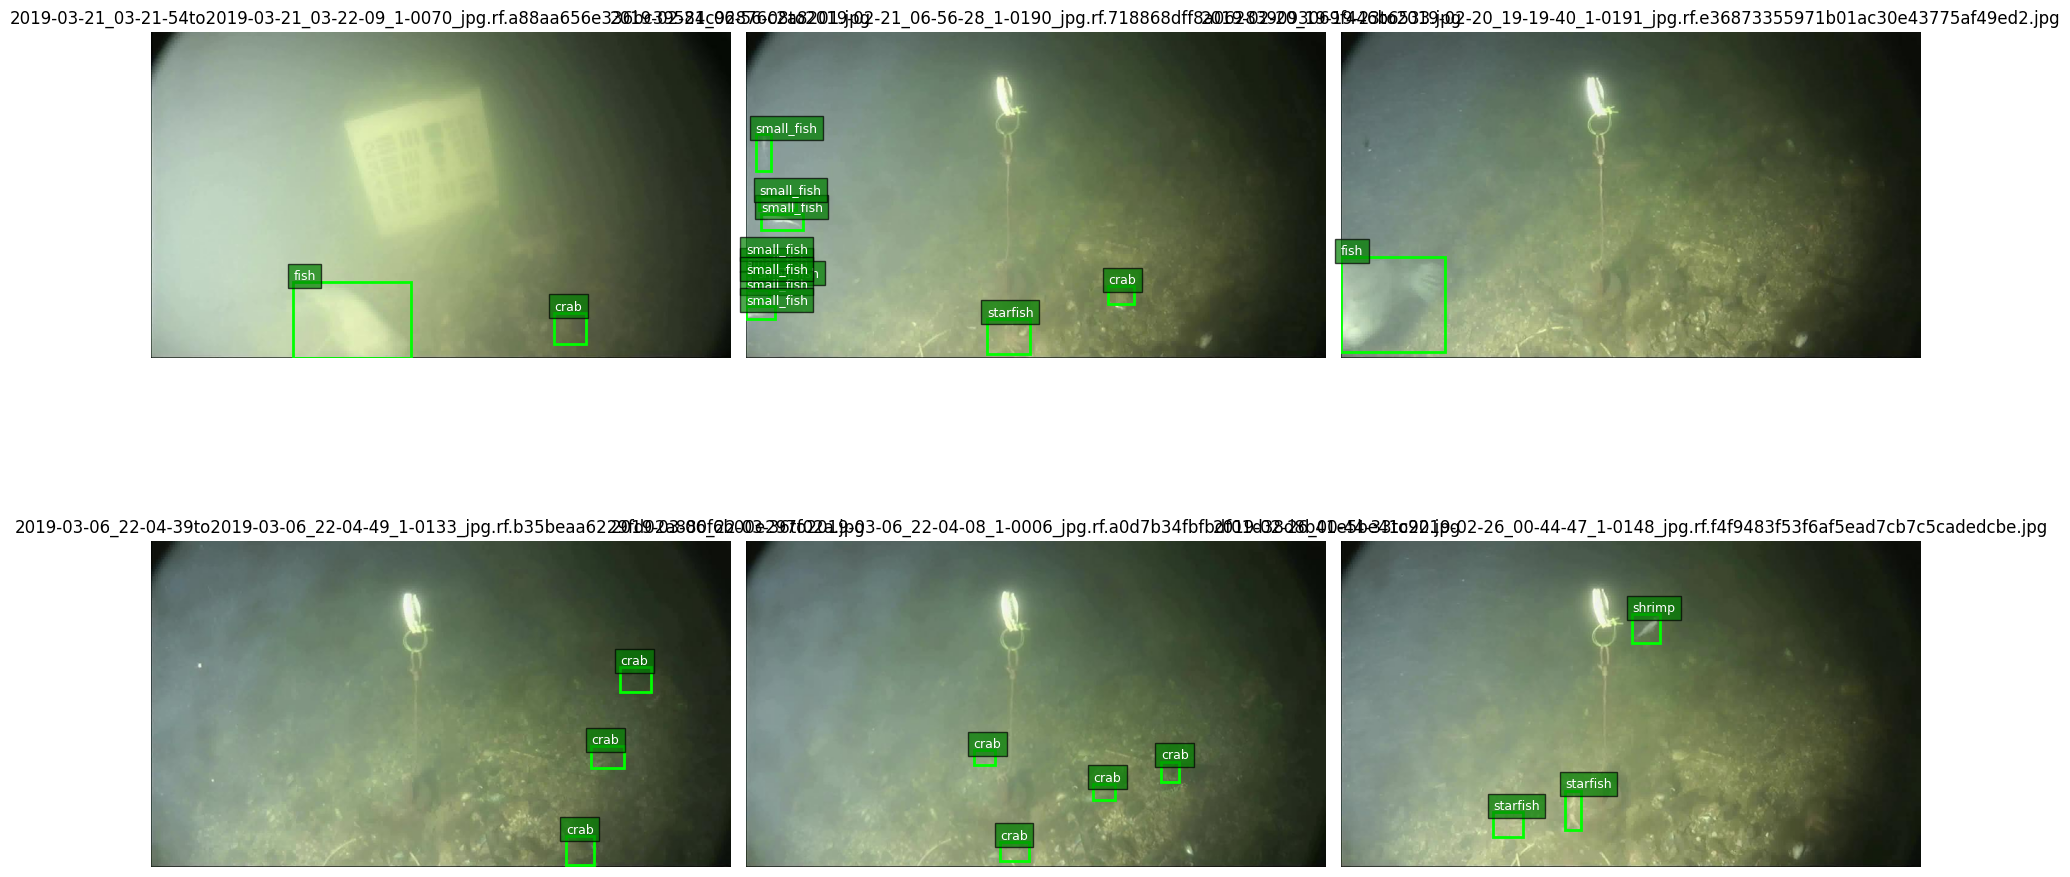

In [43]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

random.seed(42)

TRAIN_IMAGES = DATASET_ROOT / "train" / "images"
TRAIN_LABELS = DATASET_ROOT / "train" / "labels"

image_files = [
    p for p in TRAIN_IMAGES.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

selected_images = random.sample(
    image_files,
    min(6, len(image_files))
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

    label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            if not line.strip():
                continue

            class_id, x, y, w, h = map(float, line.split())

            x_center = x * width
            y_center = y * height
            box_width = w * width
            box_height = h * height

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2

            rect = patches.Rectangle(
                (x1, y1),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                max(0, y1 - 5),
                names[int(class_id)],
                color="white",
                fontsize=9,
                bbox=dict(facecolor="green", alpha=0.7)
            )

plt.tight_layout()
plt.show()

In [44]:
!pip install -q ultralytics pyyaml seaborn

In [45]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    print("WARNING: GPU is not available. Training on CPU will be considerably slower.")
    DEVICE = "cpu"
    

Ultralytics version: 8.4.202
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [46]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s pretrained model loaded successfully!")

YOLO11s pretrained model loaded successfully!


In [ ]:
from pathlib import Path

PROJECT_DIR = "/kaggle/working/brackish_yolo11"

results = model.train(
    data=str(WORKING_YAML),

    epochs=50,
    imgsz=640,
    batch=8,

    device=DEVICE,
    workers=2,

    patience=15,

    optimizer="auto",
    pretrained=True,

    save=True,
    save_period=10,

    plots=True,
    cache=False,

    project=PROJECT_DIR,
    name="underwater_yolo11s",
    exist_ok=True,

    seed=42,
    deterministic=True,

    amp=True,
    verbose=True
)

print("Training completed!")

In [47]:
from pathlib import Path

WEIGHTS_DIR = Path(
    "/kaggle/working/brackish_yolo11/underwater_yolo11s/weights"
)

if WEIGHTS_DIR.exists():
    print("Checkpoint files found:")

    for file in WEIGHTS_DIR.glob("*.pt"):
        print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")
else:
    print("Training weights folder not found.")

Checkpoint files found:
epoch0.pt 90.45 MB
epoch30.pt 90.46 MB
epoch20.pt 90.46 MB
best.pt 18.27 MB
epoch40.pt 90.46 MB
last.pt 18.27 MB
epoch10.pt 90.45 MB


In [48]:
from ultralytics import YOLO

LAST_CHECKPOINT = str(WEIGHTS_DIR / "last.pt")

model = YOLO(LAST_CHECKPOINT)

model.train(resume=True)

WARNING ⚠️ model '/kaggle/working/brackish_yolo11/underwater_yolo11s/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kob

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7973bcc5bd90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [49]:
import yaml
from pathlib import Path

print("DATASET YAML:", WORKING_YAML)

with open(WORKING_YAML, "r") as f:
    cfg = yaml.safe_load(f)

print("\nDATASET CONFIGURATION:")
print(cfg)

root = Path(cfg["path"])

for split in ["train", "val", "test"]:

    image_dir = root / cfg[split] if not Path(cfg[split]).is_absolute() else Path(cfg[split])

    label_dir = image_dir.parent.parent / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Image directory:", image_dir)
    print("Image directory exists:", image_dir.exists())
    print("Images found:", len(images))
    print("Label directory:", label_dir)
    print("Label directory exists:", label_dir.exists())
    print("Label files found:", len(labels))

    if labels:
        print("Example annotation:")
        print(labels[0].read_text()[:500])

DATASET YAML: /kaggle/working/brackish_data.yaml

DATASET CONFIGURATION:
{'path': '/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 6, 'names': ['crab', 'fish', 'jellyfish', 'shrimp', 'small_fish', 'starfish']}

TRAIN
Image directory: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/images
Image directory exists: True
Images found: 11739
Label directory: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/labels
Label directory exists: False
Label files found: 0

VAL
Image directory: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid/images
Image directory exists: True
Images found: 1467
Label directory: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/labels
Label directory exists: False
Label files found: 0

TEST
Image directory: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/images
Image dir

In [50]:
from pathlib import Path

print("Best model exists:", BEST_MODEL_PATH.exists() if isinstance(BEST_MODEL_PATH, Path) else Path(BEST_MODEL_PATH).exists())
print("Last checkpoint exists:", (WEIGHTS_DIR / "last.pt").exists())

print("\nModel class names:")
print(model.names)

NameError: name 'BEST_MODEL_PATH' is not defined

In [51]:
import pandas as pd
from pathlib import Path

csv_path = Path("/kaggle/working/runs/detect/train/results.csv")

if csv_path.exists():
    history = pd.read_csv(csv_path)
    print("Total recorded epochs:", len(history))
    display(history.tail(10))
else:
    print("results.csv not found at:", csv_path)

Total recorded epochs: 100


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
90,91,77.8647,1.86284,5.69300,2.39622,0,0,0,0,3.41420,7.23353,3.13486,0.000013,0.000013,0.000013
91,92,80.1381,2.24123,5.80032,2.48487,0,0,0,0,3.41420,7.23353,3.13486,0.000012,0.000012,0.000012
92,93,80.9496,1.91288,5.55584,2.31596,0,0,0,0,3.42216,7.26355,3.11696,0.000011,0.000011,0.000011
93,94,81.7196,1.99351,5.73265,2.48412,0,0,0,0,3.42216,7.26355,3.11696,0.000009,0.000009,0.000009
94,95,82.4348,2.53050,5.74419,2.96688,0,0,0,0,3.42216,7.26355,3.11696,0.000008,0.000008,0.000008
95,96,83.1532,2.65416,5.97182,3.00612,0,0,0,0,3.42216,7.26355,3.11696,0.000007,0.000007,0.000007
96,97,83.8886,2.20445,5.91838,2.50324,0,0,0,0,3.44514,7.37090,3.12079,0.000006,0.000006,0.000006
97,98,84.5928,2.62920,6.12978,2.82833,0,0,0,0,3.44514,7.37090,3.12079,0.000005,0.000005,0.000005
98,99,85.3256,2.11303,6.07670,2.55458,0,0,0,0,3.44514,7.37090,3.12079,0.000004,0.000004,0.000004
99,100,86.1488,2.05212,6.02711,2.46971,0,0,0,0,3.44514,7.37090,3.12079,0.000002,0.000002,0.000002


In [52]:
from pathlib import Path

for split in ["train", "valid", "test"]:

    label_dir = DATASET_ROOT / split / "labels"

    print(f"\n{split.upper()}")
    print("Path:", label_dir)
    print("Exists:", label_dir.exists())

    if label_dir.exists():
        print("TXT files:", len(list(label_dir.glob("*.txt"))))


TRAIN
Path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/train/labels
Exists: True
TXT files: 11739

VALID
Path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/valid/labels
Exists: True
TXT files: 1467

TEST
Path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels
Exists: True
TXT files: 1468


In [53]:
import yaml

correct_config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": [
        "crab",
        "fish",
        "jellyfish",
        "shrimp",
        "small_fish",
        "starfish"
    ]
}

with open(WORKING_YAML, "w") as f:
    yaml.safe_dump(correct_config, f, sort_keys=False)

print("Corrected YAML:")
print(open(WORKING_YAML).read())

Corrected YAML:
path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- crab
- fish
- jellyfish
- shrimp
- small_fish
- starfish



In [54]:
for split in ["train", "valid", "test"]:

    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(
        split,
        "| Images:", len(images),
        "| Labels:", len(labels)
    )

train | Images: 11739 | Labels: 11739
valid | Images: 1467 | Labels: 1467
test | Images: 1468 | Labels: 1468


In [55]:
import yaml
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset"
)

WORKING_YAML = Path("/kaggle/working/brackish_data.yaml")

config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": [
        "crab",
        "fish",
        "jellyfish",
        "shrimp",
        "small_fish",
        "starfish"
    ]
}

with open(WORKING_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(WORKING_YAML.read_text())

path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- crab
- fish
- jellyfish
- shrimp
- small_fish
- starfish



In [56]:
from pathlib import Path

label_dir = DATASET_ROOT / "train" / "labels"

sample_labels = list(label_dir.glob("*.txt"))[:5]

for file in sample_labels:
    print(f"\n{file.name}")
    print(file.read_text()[:500])


2019-02-20_19-01-02to2019-02-20_19-01-13_1-0004_jpg.rf.5352b284e907cdc9e4276e14f5603115.txt


2019-02-20_19-01-02to2019-02-20_19-01-13_1-0005_jpg.rf.1734dbcac53c80893dcbfbe72387d94b.txt


2019-02-20_19-01-02to2019-02-20_19-01-13_1-0006_jpg.rf.da9f39fdfd26b02c3c874e4eb1110063.txt


2019-02-20_19-01-02to2019-02-20_19-01-13_1-0008_jpg.rf.4fb1155b5122e6eb00feeea617d55c24.txt


2019-02-20_19-01-02to2019-02-20_19-01-13_1-0009_jpg.rf.bb2de4b071f763814a55c5af0487d4de.txt



In [57]:
from pathlib import Path

for p in Path("/kaggle/working").rglob("best.pt"):
    print("BEST MODEL:", p)

for p in Path("/kaggle/working").rglob("last.pt"):
    print("LAST MODEL:", p)

BEST MODEL: /kaggle/working/runs/detect/train/weights/best.pt
BEST MODEL: /kaggle/working/brackish_yolo11/underwater_yolo11s/weights/best.pt
LAST MODEL: /kaggle/working/runs/detect/train/weights/last.pt
LAST MODEL: /kaggle/working/brackish_yolo11/underwater_yolo11s/weights/last.pt


In [58]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset"
)

for split in ["train", "valid", "test"]:
    label_dir = DATASET_ROOT / split / "labels"

    valid_count = 0
    invalid_files = []

    for file in label_dir.glob("*.txt"):
        try:
            for line in file.read_text().splitlines():
                if not line.strip():
                    continue

                values = line.split()

                if len(values) != 5:
                    raise ValueError("Expected 5 values")

                cls, x, y, w, h = map(float, values)

                if (
                    not cls.is_integer()
                    or not 0 <= cls < 6
                    or not all(0 <= v <= 1 for v in [x, y, w, h])
                    or w <= 0 or h <= 0
                ):
                    raise ValueError("Invalid annotation")

            valid_count += 1

        except Exception as e:
            invalid_files.append((file.name, str(e)))

    print(f"\n{split.upper()}")
    print("Valid label files:", valid_count)
    print("Invalid label files:", len(invalid_files))
    print("Examples:", invalid_files[:5])


TRAIN
Valid label files: 11739
Invalid label files: 0
Examples: []

VALID
Valid label files: 1467
Invalid label files: 0
Examples: []

TEST
Valid label files: 1468
Invalid label files: 0
Examples: []


In [59]:
import yaml

WORKING_YAML = "/kaggle/working/brackish_data.yaml"

config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": [
        "crab",
        "fish",
        "jellyfish",
        "shrimp",
        "small_fish",
        "starfish"
    ]
}

with open(WORKING_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(open(WORKING_YAML).read())

path: /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- crab
- fish
- jellyfish
- shrimp
- small_fish
- starfish



In [60]:
from ultralytics import YOLO
from pathlib import Path

# Load pretrained YOLO11s
model = YOLO("yolo11s.pt")

# Fresh training
results = model.train(
    data=WORKING_YAML,

    epochs=50,
    imgsz=640,
    batch=8,

    device=0,
    workers=2,

    optimizer="auto",
    patience=15,

    pretrained=True,
    resume=False,

    project="/kaggle/working/brackish_yolo11",
    name="yolo11s_50ep_corrected",
    exist_ok=False,

    save=True,
    save_period=10,

    plots=True,
    val=True,

    amp=True,
    cache=False,

    seed=42,
    deterministic=True,

    verbose=True
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/brackish_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_50ep_corrected, nbs=64, nms=None, opset=None, o

In [61]:
from ultralytics import YOLO

BEST_MODEL = (
    "/kaggle/working/brackish_yolo11/"
    "yolo11s_50ep_corrected/weights/best.pt"
)

model = YOLO(BEST_MODEL)

test_results = model.val(
    data=WORKING_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

print("\nFINAL TEST RESULTS")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 0.2±0.1 MB/s, size: 25.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels... 1468 images, 229 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1468/1468 18.8it/s 1:180.1sss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 184/184 1.4it/s 2:100.6ss
                   all       1468       3466       0.98      0.961      0.979      0.799
                  crab        614       1279      0.98

In [62]:
model.predict(
    source=str(DATASET_ROOT / "test" / "images"),
    imgsz=640,
    conf=0.25,
    save=True,
    device=0
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1468 /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/images/2019-02-20_19-01-02to2019-02-20_19-01-13_1-0007_jpg.rf.14c6af7cc823485d0cf90dd152bfdfe3.jpg: 384x640 (no detections), 16.0ms
image 2/1468 /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/images/2019-02-20_19-01-02to2019-02-20_19-01-13_1-0013_jpg.rf.c243ba3619fef84a841bb17e34b782dd.jpg: 384x640 (no detections), 16.0ms
image 3/1468 /kaggle/input/

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'crab', 1: 'fish', 2: 'jellyfish', 3: 'shrimp', 4: 'small_fish', 5: 'starfish'}
 obb: None
 orig_img: array([[[  0,   2,   0],
         [  2,   7,   5],
         [  7,  12,  10],
         ...,
         [  9,  14,  12],
         [  9,  14,  12],
         [  9,  14,  12]],
 
        [[  0,   2,   0],
         [  2,   7,   5],
         [  7,  12,  10],
         ...,
         [  9,  14,  12],
         [  9,  14,  12],
         [  9,  14,  12]],
 
        [[  0,   2,   0],
         [  2,   7,   5],
         [  7,  12,  10],
         ...,
         [  9,  14,  12],
         [  9,  14,  12],
         [  9,  14,  12]],
 
        ...,
 
        [[ 14,  25,  17],
         [ 86,  97,  89],
         [119, 130, 122],
         ...,
         [  9,  14,  12],
         [  9,  14,  12],
         [  9,  14,  12]],
 
        [[ 37,  44,  39],
 

Predicted images: 1468


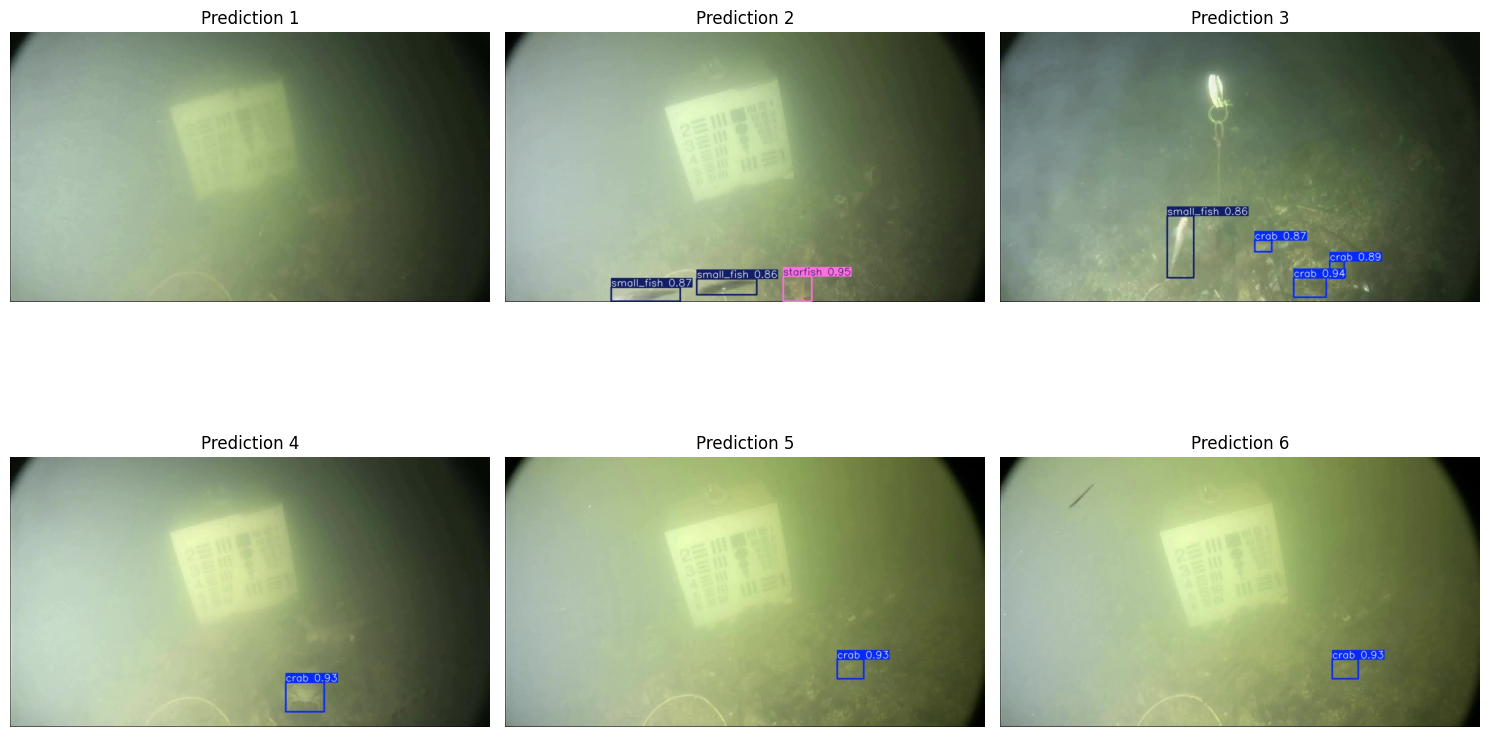

In [63]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

images = glob.glob(
    "/kaggle/working/runs/detect/predict/*.jpg"
)

print("Predicted images:", len(images))

plt.figure(figsize=(15, 10))

for i, img_path in enumerate(images[:6]):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Image.open(img_path))
    plt.axis("off")
    plt.title(f"Prediction {i+1}")

plt.tight_layout()
plt.show()

In [64]:
test_results = model.val(
    data=WORKING_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

print("Test Precision:", test_results.box.mp)
print("Test Recall:", test_results.box.mr)
print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 54.1±9.8 MB/s, size: 24.0 KB)
val: Scanning /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels... 1468 images, 229 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1468/1468 828.1it/s 1.8s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 184/184 12.9it/s 14.2s0.1s
                   all       1468       3466       0.98      0.961      0.979      0.799
                  crab        614       1279      0.989      0.991      0.995      0.869
                  fish        321        321      0.984      0.977      0.994      0.856
             jellyfish        

In [65]:
from pathlib import Path
import shutil

SOURCE = Path(
    "/kaggle/working/brackish_yolo11/yolo11s_50ep_corrected"
)

DEST = Path("/kaggle/working/Final_Underwater_Project")
DEST.mkdir(exist_ok=True)

# Copy trained weights
shutil.copytree(
    SOURCE / "weights",
    DEST / "weights",
    dirs_exist_ok=True
)

# Copy training plots and results
for file in SOURCE.iterdir():
    if file.is_file():
        shutil.copy2(file, DEST / file.name)

# Copy test evaluation plots
VAL_DIR = Path("/kaggle/working/runs/detect/val-2")

if VAL_DIR.exists():
    shutil.copytree(
        VAL_DIR,
        DEST / "test_evaluation",
        dirs_exist_ok=True
    )

# Copy dataset YAML
shutil.copy2(
    "/kaggle/working/brackish_data.yaml",
    DEST / "brackish_data.yaml"
)

print("Project files collected:", DEST)
print("Files:", [p.name for p in DEST.iterdir()])

Project files collected: /kaggle/working/Final_Underwater_Project
Files: ['BoxR_curve.png', 'results.csv', 'val_batch2_pred.jpg', 'labels.jpg', 'results.png', 'args.yaml', 'val_batch2_labels.jpg', 'confusion_matrix_normalized.png', 'train_batch58721.jpg', 'val_batch1_pred.jpg', 'BoxP_curve.png', 'train_batch58722.jpg', 'val_batch1_labels.jpg', 'val_batch0_labels.jpg', 'weights', 'BoxPR_curve.png', 'train_batch58720.jpg', 'confusion_matrix.png', 'train_batch1.jpg', 'test_evaluation', 'brackish_data.yaml', 'train_batch2.jpg', 'BoxF1_curve.png', 'train_batch0.jpg', 'val_batch0_pred.jpg']


In [66]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/Final_Underwater_Project",
    "zip",
    "/kaggle/working/Final_Underwater_Project"
)

print("ZIP created:", zip_path)

ZIP created: /kaggle/working/Final_Underwater_Project.zip


In [67]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

# Load your trained YOLO11s model
BEST_MODEL = "/kaggle/working/brackish_yolo11/yolo11s_50ep_corrected/weights/best.pt"
DATA_YAML = "/kaggle/working/brackish_data.yaml"

model = YOLO(BEST_MODEL)

# Evaluate on the test dataset and generate plots
results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/kaggle/working/final_plots",
    name="test_evaluation",
    exist_ok=True
)

# Output directory
PLOT_DIR = Path(results.save_dir)

print("Plots saved in:", PLOT_DIR)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 60.0±14.1 MB/s, size: 23.8 KB)
val: Scanning /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test/labels... 1468 images, 229 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1468/1468 825.9it/s 1.8s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ssaloni23/brackish-underwater-fish-dataset/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 184/184 13.0it/s 14.1s0.1s
                   all       1468       3466       0.98      0.961      0.979      0.799
                  crab        614       1279      0.989      0.991      0.995      0.869
                  fish        321        321      0.984      0.977      0.994      0.856
             jellyfish       

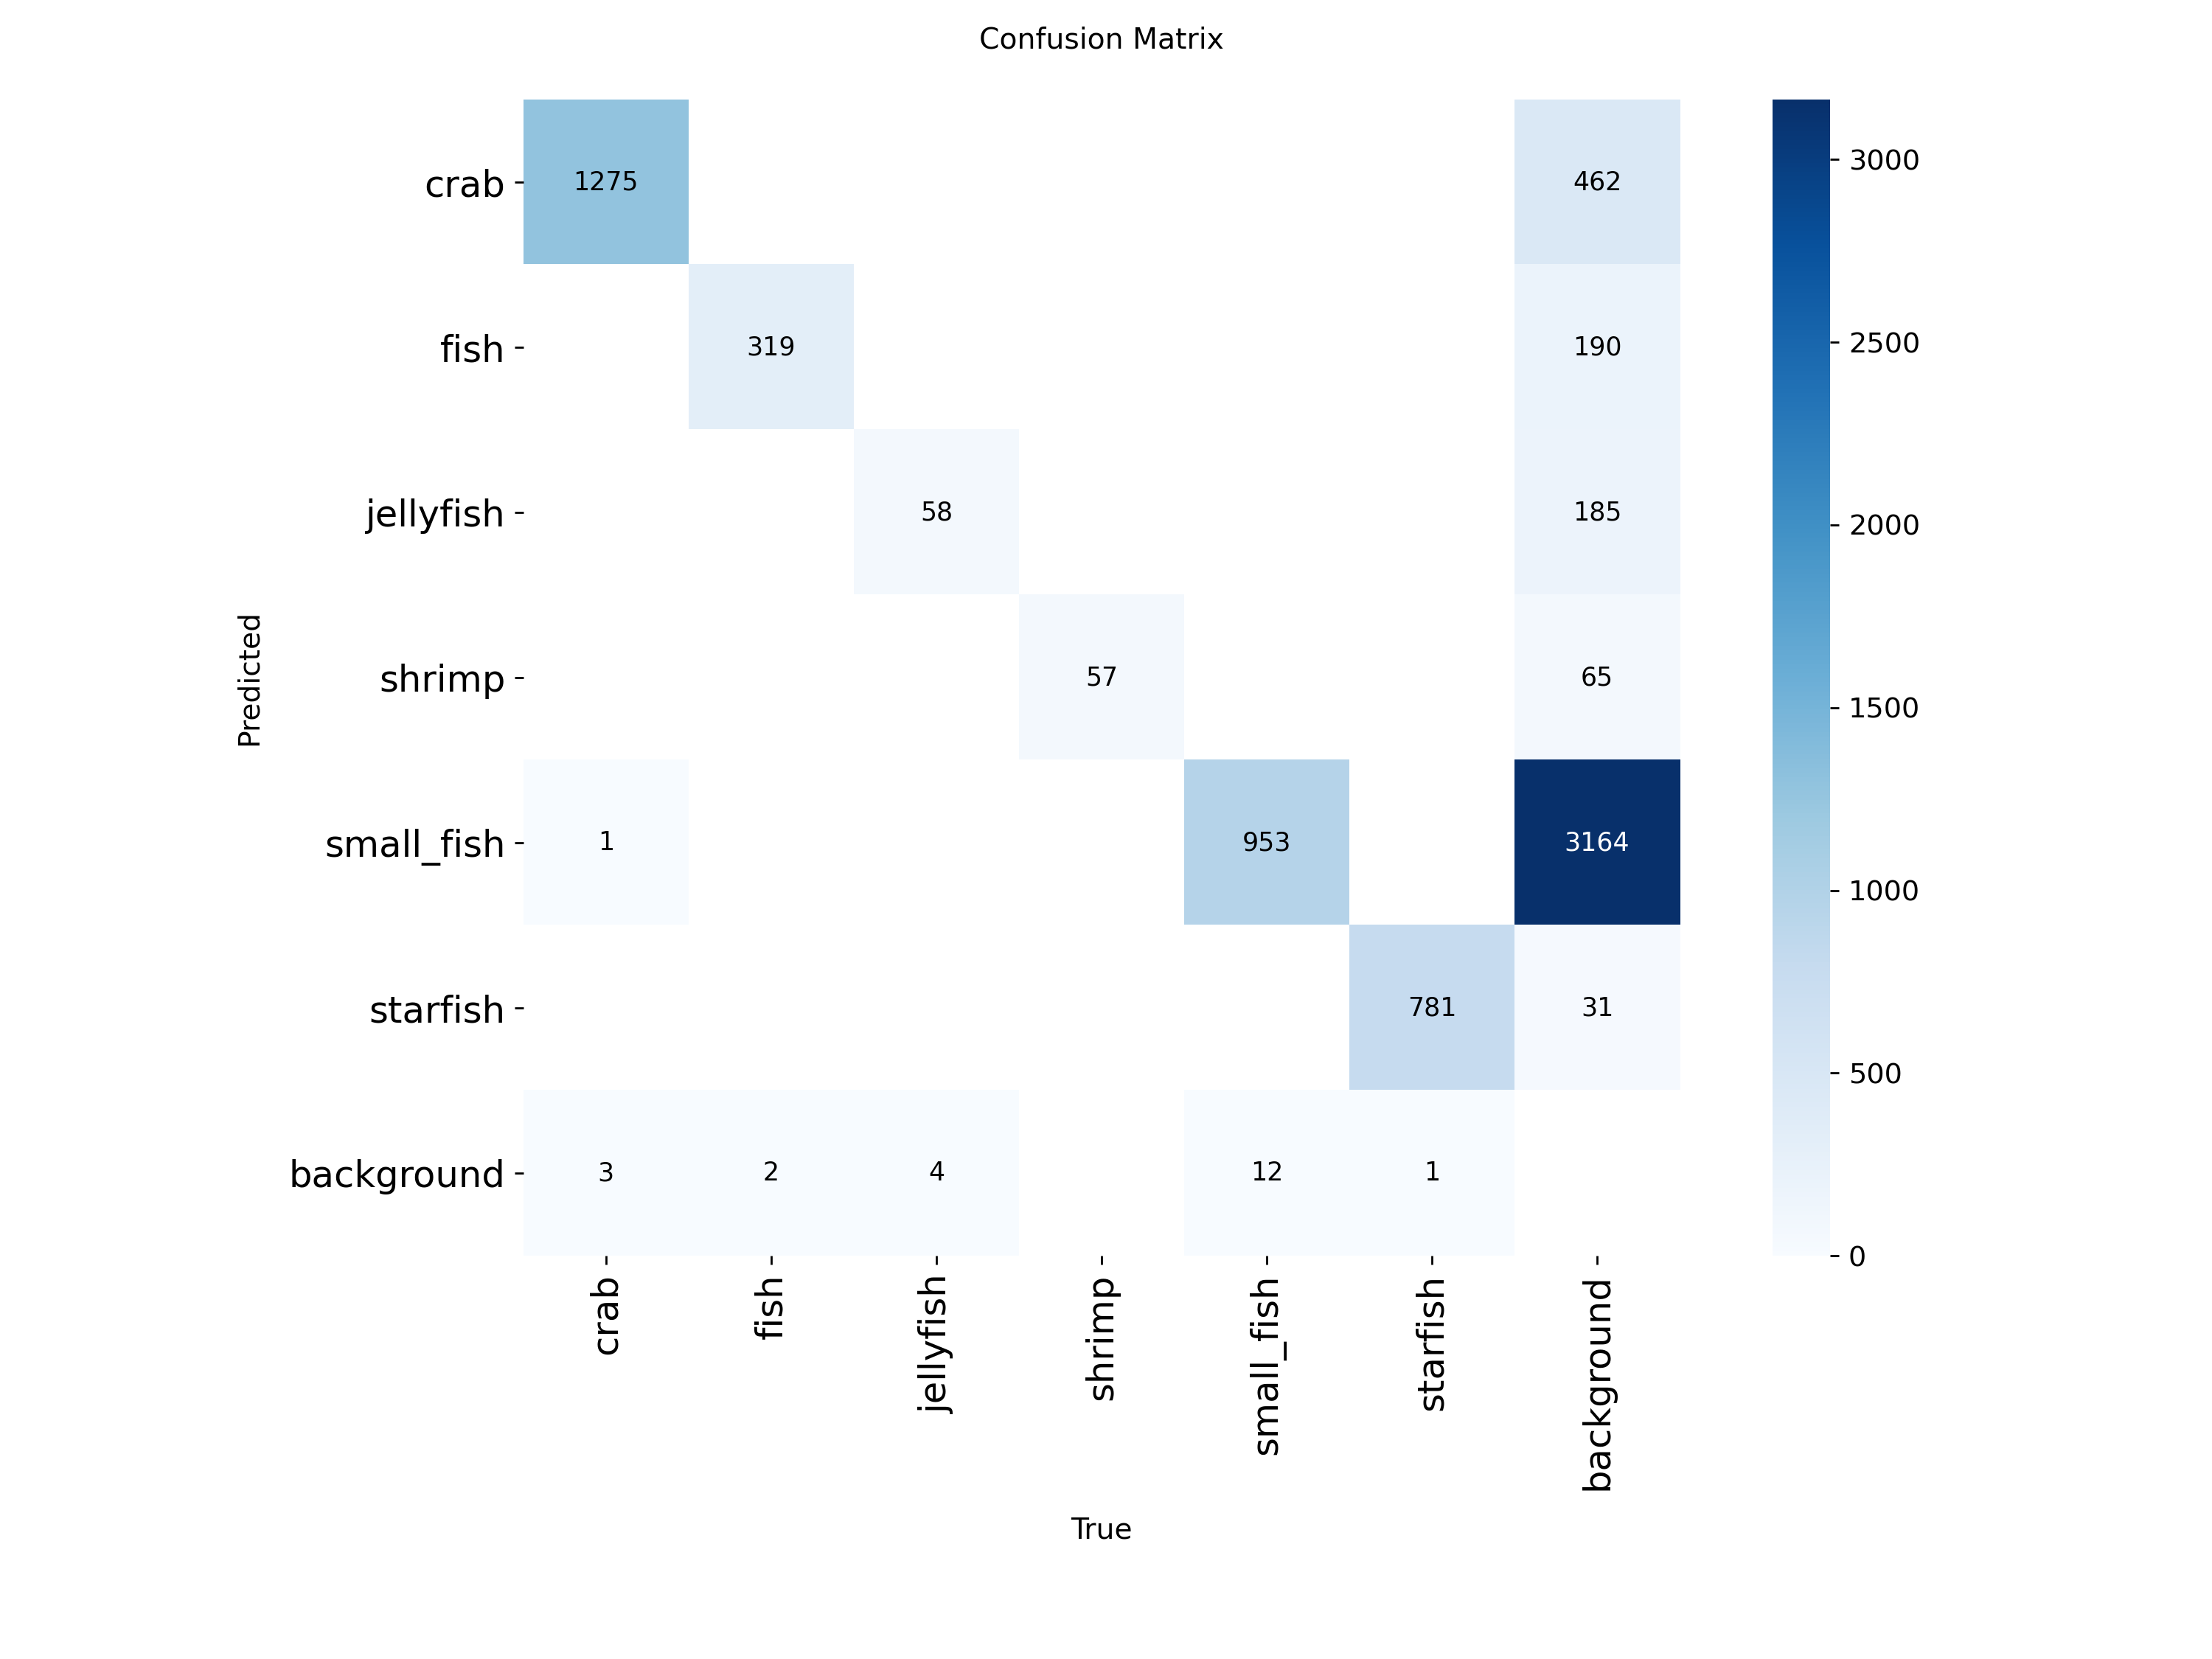

In [68]:
confusion_matrix = PLOT_DIR / "confusion_matrix.png"

display(Image(filename=str(confusion_matrix)))

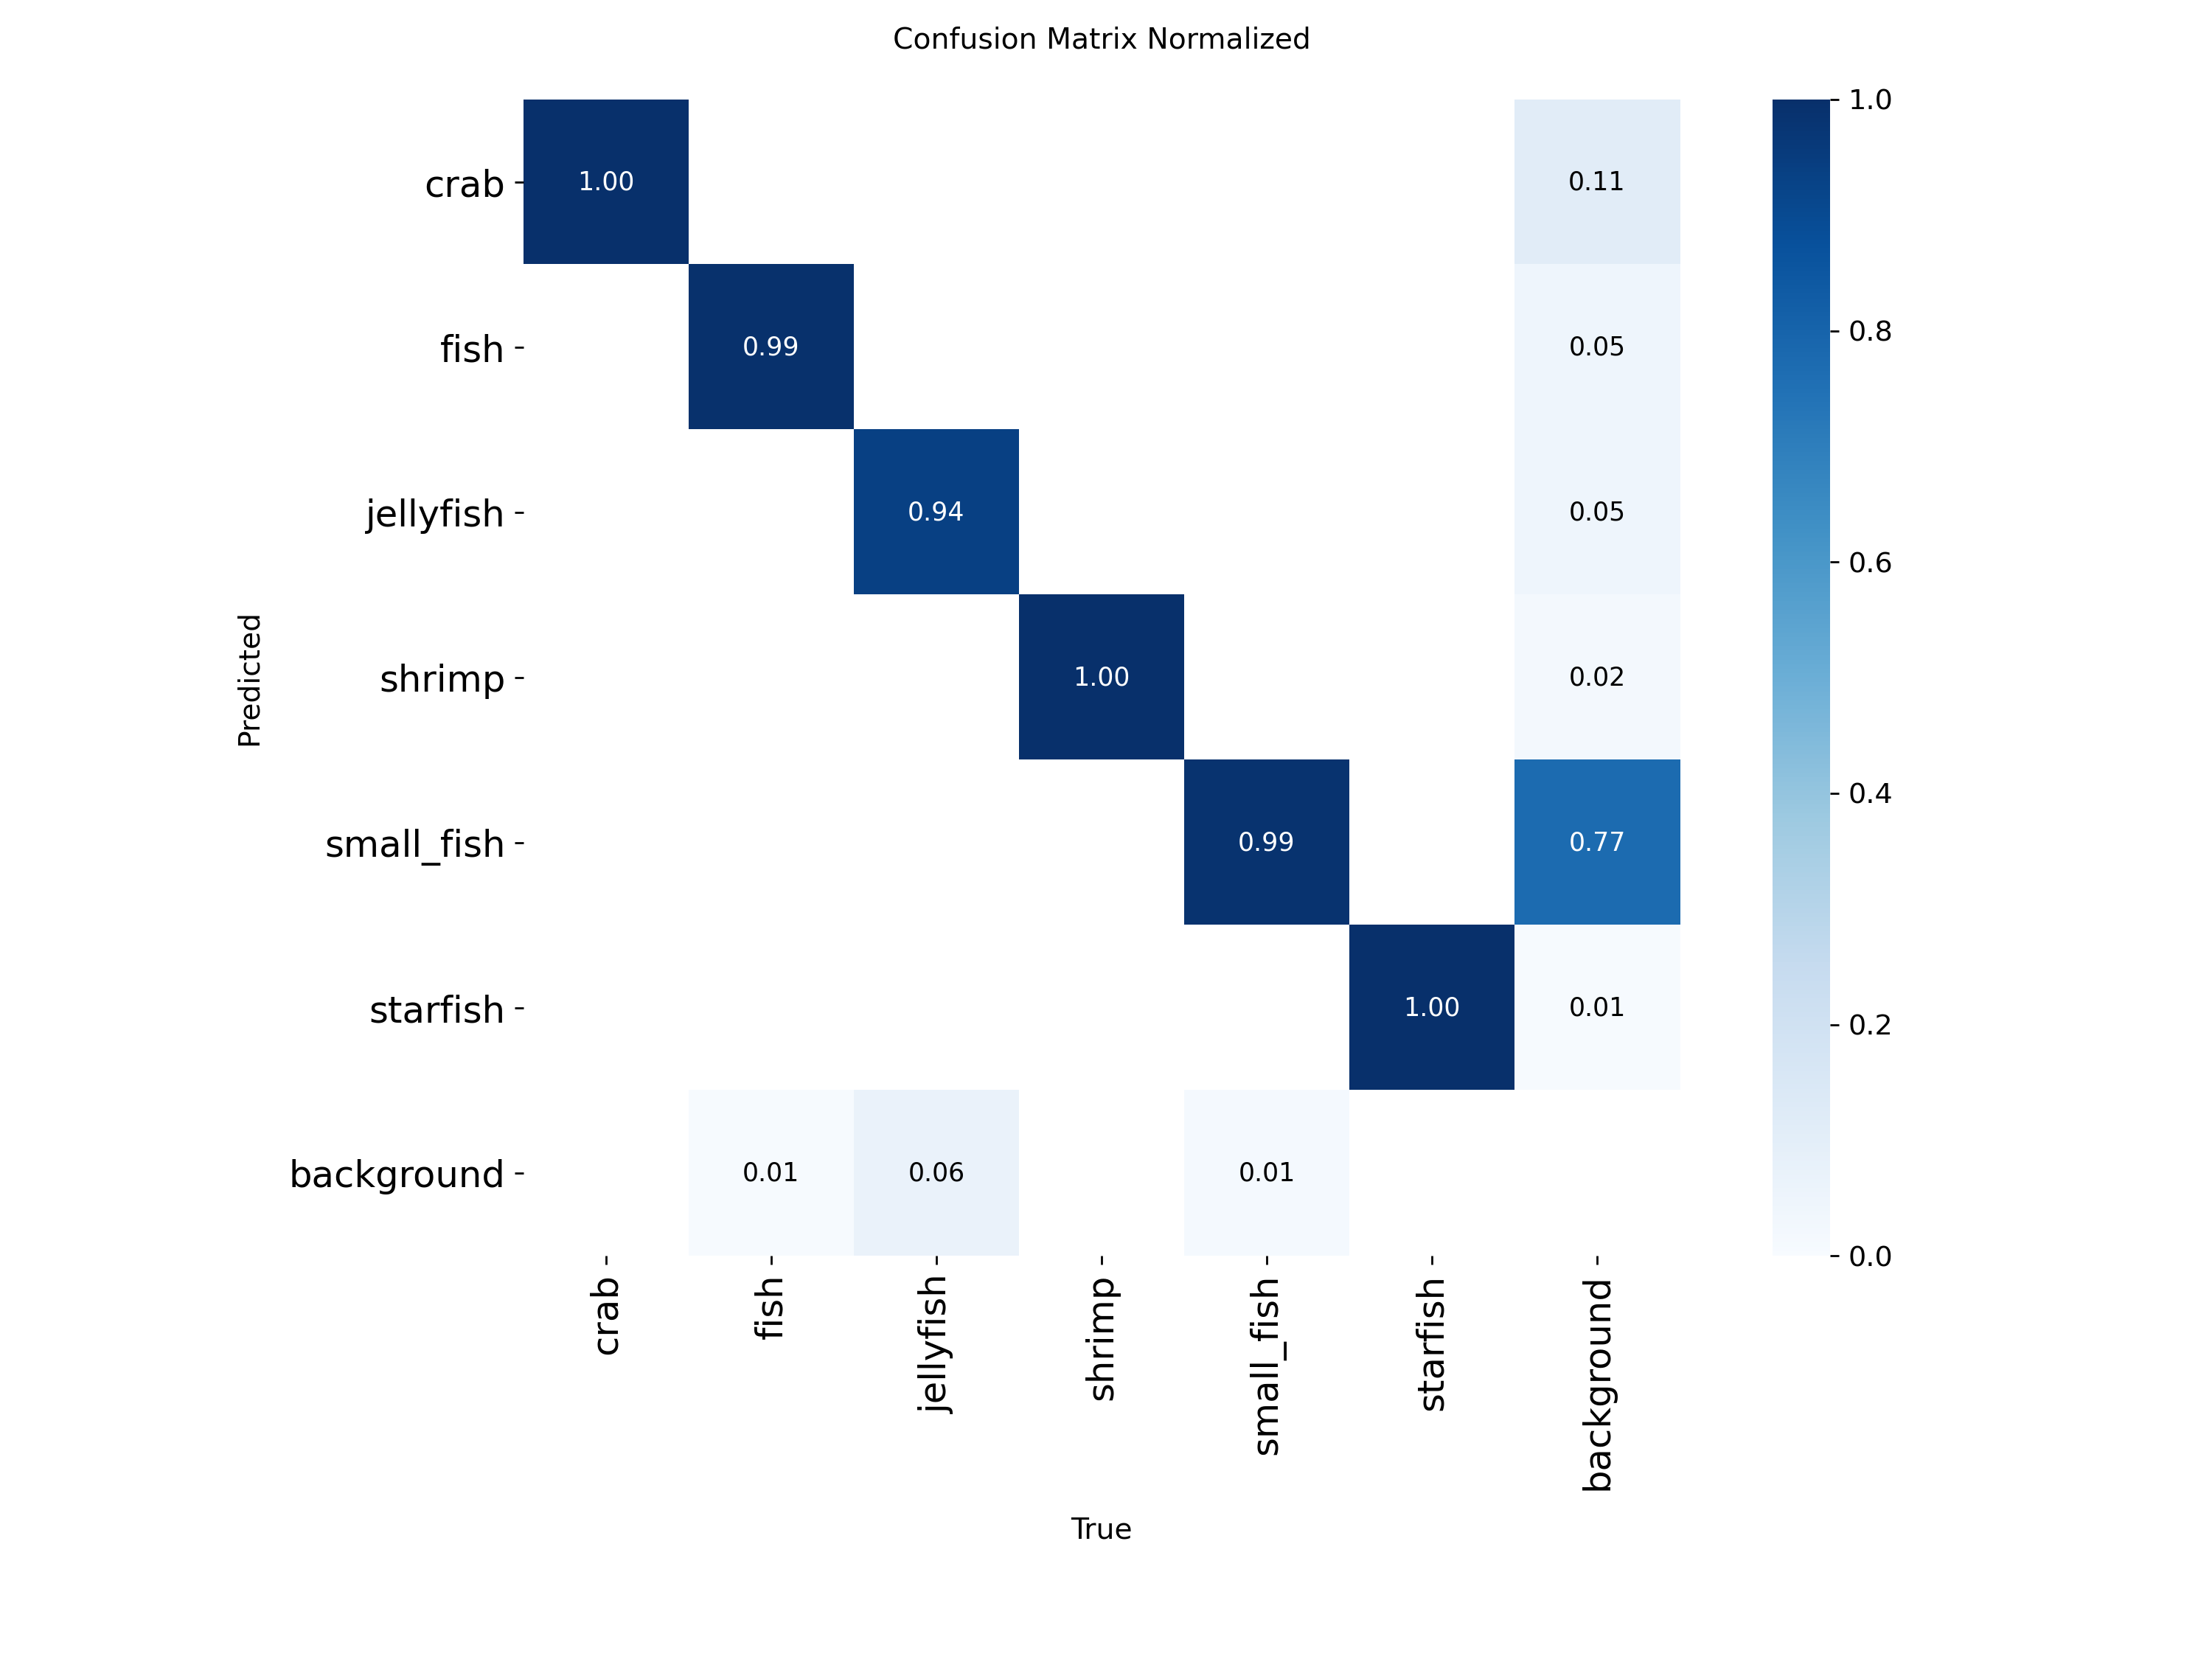

In [69]:
normalized_matrix = PLOT_DIR / "confusion_matrix_normalized.png"

display(Image(filename=str(normalized_matrix)))

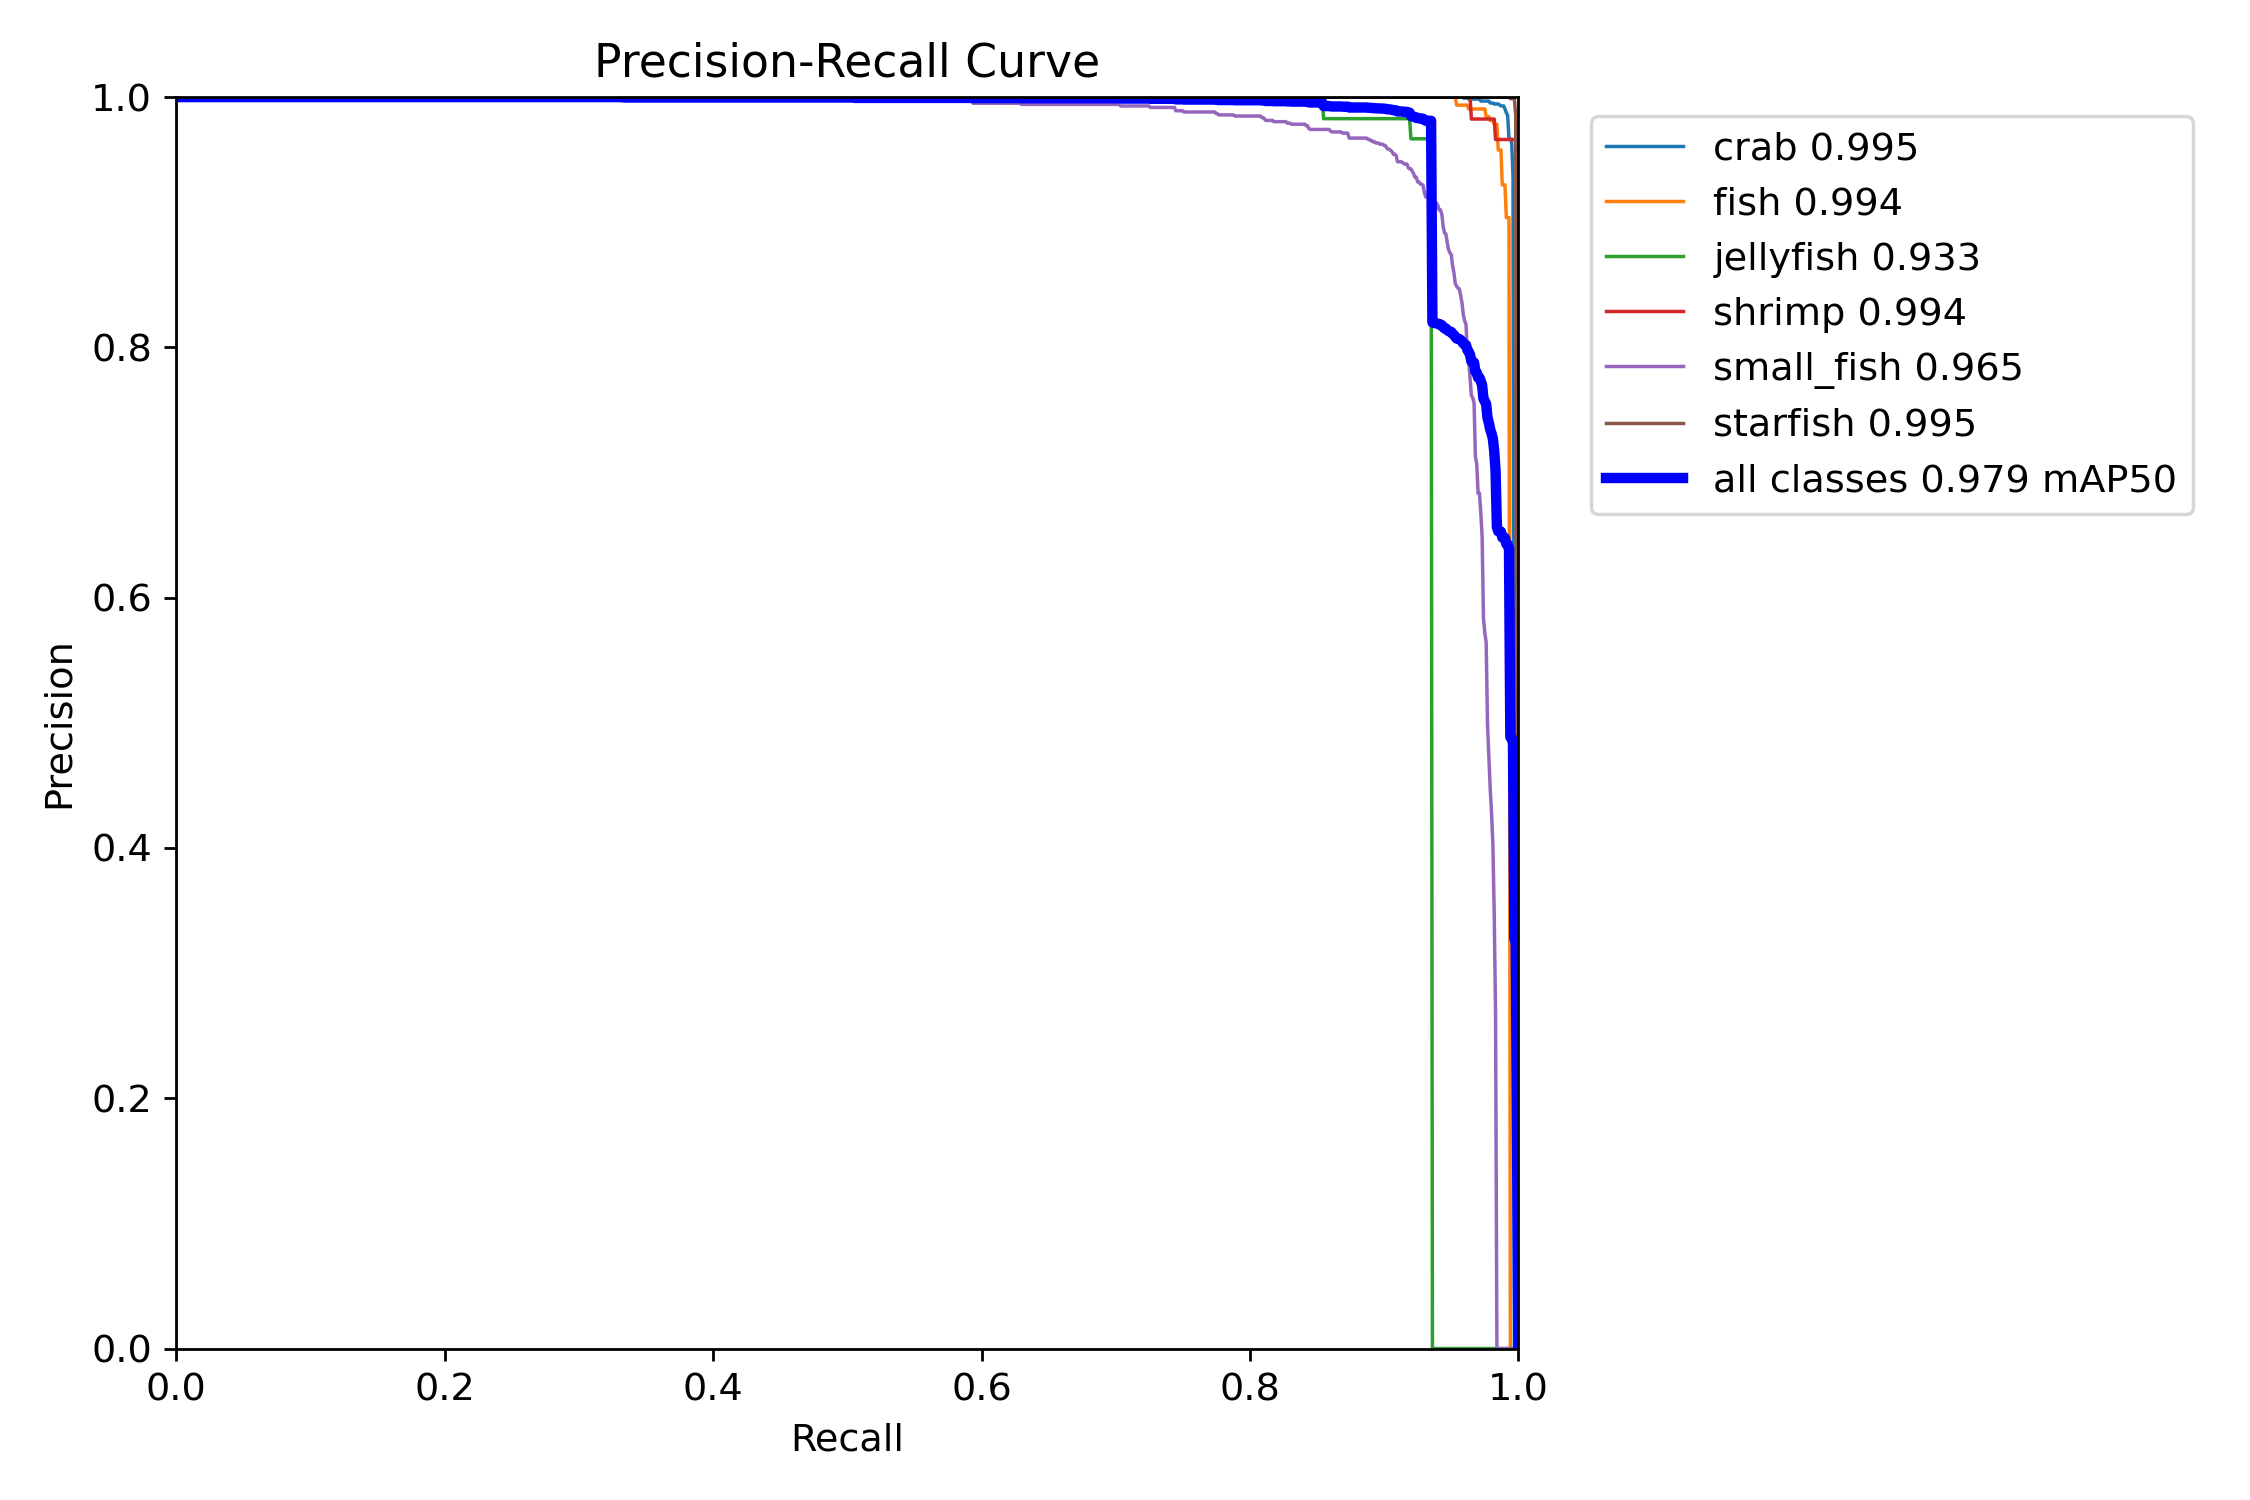

In [70]:
pr_curve = PLOT_DIR / "BoxPR_curve.png"

display(Image(filename=str(pr_curve)))

In [71]:
import shutil

FINAL_DIR = Path("/kaggle/working/Final_Underwater_Project")
FINAL_DIR.mkdir(exist_ok=True)

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png"
]:
    source = PLOT_DIR / filename

    if source.exists():
        shutil.copy(source, FINAL_DIR / filename)
        print("Saved:", filename)
    else:
        print("Not found:", filename)

Saved: confusion_matrix.png
Saved: confusion_matrix_normalized.png
Saved: BoxPR_curve.png
